
# ***Analisis Sentimen Ulasan Aplikasi Steam di Playstore dengan Machine Learning***

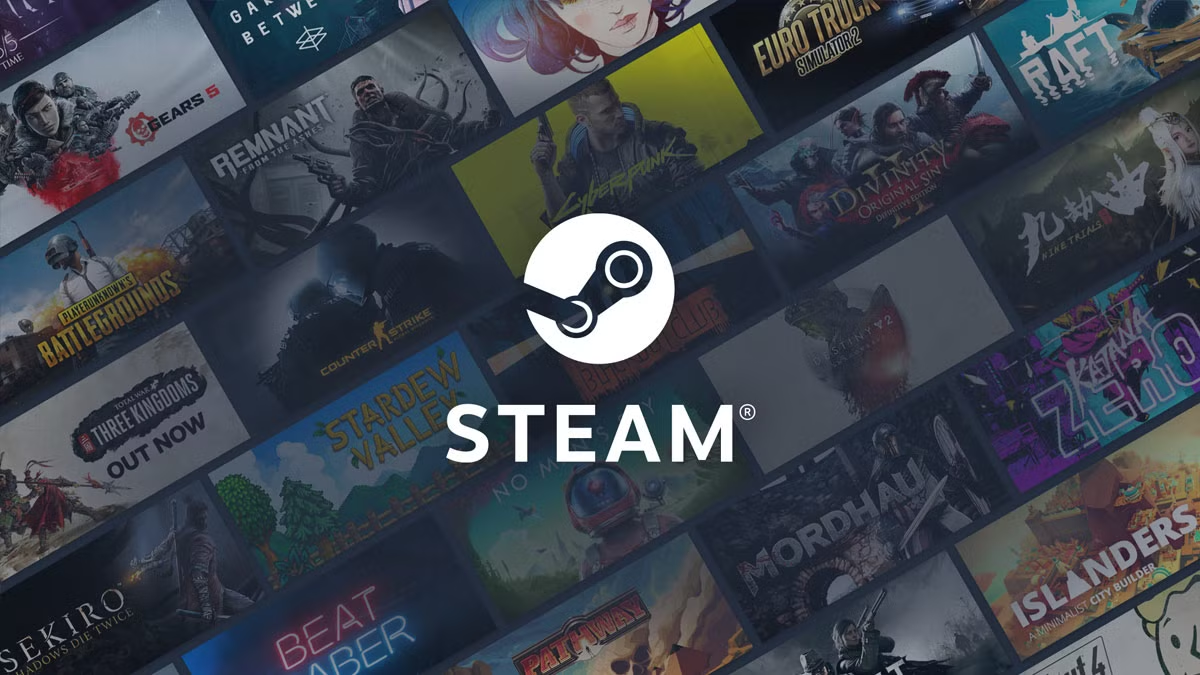


# ***SCRAPING DATA***

In [ ]:
# Menginstal pustaka google-play-scraper untuk melakukan scraping data ulasan langsung dari Google Play Store
!pip install google-play-scraper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 559.7 kB/s eta 0:00:00


In [ ]:
# Mengimpor modul dan pustaka yang diperlukan untuk scraping, manipulasi waktu, penulisan CSV, dan hashing
from google_play_scraper import reviews, Sort
from datetime import datetime
import csv
import hashlib
import difflib

# Menentukan ID aplikasi Steam Link di Play Store
app_id = 'com.valvesoftware.android.steam.community'

# Fungsi untuk mengambil ulasan berdasarkan rentang tanggal tertentu
def get_reviews_by_date(app_id, lang='id', country='id', count=100000, start_date='2023-09-01', end_date='2026-09-30'):
    all_reviews = []
    continuation_token = None

    # Mengonversi string tanggal menjadi objek datetime untuk perbandingan
    start_dt = datetime.strptime(start_date, "%Y-%m-%d")
    end_dt = datetime.strptime(end_date, "%Y-%m-%d")

    while True:
        try:
            # Mengambil ulasan dari Play Store menggunakan API scraper
            result, continuation_token = reviews(
                app_id,
                lang=lang,
                country=country,
                sort=Sort.NEWEST,
                count=count,
                continuation_token=continuation_token
            )

            if not result:
                break

            # Memfilter ulasan yang masuk dalam rentang tanggal yang diinginkan
            for r in result:
                review_date = r.get('at')
                if review_date is None:
                    continue

                if start_dt <= review_date <= end_dt:
                    # Menyimpan informasi penting dari setiap ulasan
                    rec = {
                        'reviewId': r.get('reviewId'),
                        'userName': r.get('userName'),
                        'userImage': r.get('userImage'),
                        'score': r.get('score'),
                        'at': review_date.isoformat(),
                        'content': r.get('content'),
                        'thumbsUpCount': r.get('thumbsUp'),
                        'replyContent': r.get('replyContent'),
                        'replyAt': r.get('replyAt').isoformat() if r.get('replyAt') else None
                    }
                    all_reviews.append(rec)
                elif review_date < start_dt:
                    continuation_token = None
                    break

            if continuation_token is None:
                break

        except Exception as e:
            print("Error:", e)
            break

    return all_reviews

# Fungsi untuk membuat sidik jari (fingerprint) teks secara deterministik
def fingerprint_text(text, n_chars=80):
    if not text:
        return None
    t = text.strip().lower()[:n_chars]
    return hashlib.sha1(t.encode('utf-8')).hexdigest()

# Fungsi untuk membuat sidik jari dari URL gambar pengguna
def fingerprint_image(url):
    if not url:
        return None
    return hashlib.sha1(url.encode('utf-8')).hexdigest()

# Fungsi heuristik untuk mengidentifikasi dan mengelompokkan ID pengguna yang anonim
def assign_probable_user_id(reviews):
    for r in reviews:
        uname = (r.get('userName') or '').strip()
        if uname and uname.lower() != 'pengguna google':
            pid = 'name:' + '_'.join(uname.split()).lower()
        else:
            img_fp = fingerprint_image(r.get('userImage'))
            if img_fp:
                pid = 'img:' + img_fp
            else:
                txt_fp = fingerprint_text(r.get('content') or '')
                if txt_fp:
                    pid = 'txt:' + txt_fp
                else:
                    pid = 'rid:' + (r.get('reviewId') or 'unknown')
        r['probable_user_id'] = pid

    # Menggabungkan ID pengguna yang mengirimkan ulasan teks yang sangat mirip
    TEXT_SIM_THRESHOLD = 0.92
    text_groups = {}
    for r in reviews:
        if r['probable_user_id'].startswith('txt:'):
            base_txt = (r.get('content') or '').strip()
            merged = False
            for key, rep in text_groups.items():
                ratio = difflib.SequenceMatcher(None, base_txt, rep['sample']).ratio()
                if ratio >= TEXT_SIM_THRESHOLD:
                    r['probable_user_id'] = key
                    merged = True
                    break
            if not merged:
                key = r['probable_user_id']
                text_groups[key] = {'sample': base_txt}
    return reviews

# Fungsi untuk menyimpan seluruh data hasil scraping ke file CSV
def save_reviews_to_csv(reviews, filename='hasil_scraper_ulasan_app_steam.csv'):
    headers = ['probable_user_id','reviewId','userName','userImage','score','at','content','thumbsUpCount','replyContent','replyAt']
    with open(filename, 'w', encoding='utf-8', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=headers)
        writer.writeheader()
        for r in reviews:
            writer.writerow({k: r.get(k) for k in headers})
    print(f"Saved {len(reviews)} rows to {filename}")

# Menjalankan proses scraping data
filtered_reviews = get_reviews_by_date(
    app_id,
    lang='id',
    country='id',
    count=100000,
    start_date='2023-09-01',
    end_date='2026-09-30'
)

print("Total reviews fetched:", len(filtered_reviews))

# Memproses ID pengguna dan menyimpan data jika ulasan berhasil didapatkan
if filtered_reviews:
    filtered_reviews = assign_probable_user_id(filtered_reviews)
    for i, r in enumerate(filtered_reviews[:10], 1):
        print(f"\n[{i}] probable_user_id: {r['probable_user_id']}")
        print(" userName:", r['userName'])
        print(" userImage:", r['userImage'])
        print(" date:", r['at'])
        print(" score:", r['score'])
        print(" content:", (r['content'] or "")[:200])

    save_reviews_to_csv(filtered_reviews)

Total reviews fetched: 2351

[1] probable_user_id: img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911
 userName: Pengguna Google
 userImage: https://play-lh.googleusercontent.com/EGemoI2NTXmTsBVtJqk8jxF9rh8ApRWfsIMQSt2uE4OcpQqbFu7f7NbTK05lx80nuSijCz7sc3a277R67g
 date: 2026-09-28T23:07:22
 score: 1
 content: useless apk 🤣, can't log in. fitur lupa password tidak bekerja sama sekali 🤣🤣

[2] probable_user_id: img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911
 userName: Pengguna Google
 userImage: https://play-lh.googleusercontent.com/EGemoI2NTXmTsBVtJqk8jxF9rh8ApRWfsIMQSt2uE4OcpQqbFu7f7NbTK05lx80nuSijCz7sc3a277R67g
 date: 2026-09-28T13:46:23
 score: 1
 content: ga bisa verifikasi kalo gw manusia

[3] probable_user_id: img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911
 userName: Pengguna Google
 userImage: https://play-lh.googleusercontent.com/EGemoI2NTXmTsBVtJqk8jxF9rh8ApRWfsIMQSt2uE4OcpQqbFu7f7NbTK05lx80nuSijCz7sc3a277R67g
 date: 2026-09-28T11:13:16
 score: 1
 content: kok jadi busuk gini, minta reset p

# ***TEXT PREPROCESSING DATA***

In [ ]:
# Mengimpor pustaka pandas untuk memanipulasi dataset
import pandas as pd
# Membaca dataset hasil scraping dari file CSV
data = pd.read_csv("hasil_scraper_ulasan_app_steam.csv")

In [ ]:
# Menampilkan informasi ringkas mengenai dataset seperti tipe data kolom dan jumlah nilai non-null
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2351 entries, 0 to 2350
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   probable_user_id  2351 non-null   object 
 1   reviewId          2351 non-null   object 
 2   userName          2351 non-null   object 
 3   userImage         2351 non-null   object 
 4   score             2351 non-null   int64  
 5   at                2351 non-null   object 
 6   content           2351 non-null   object 
 7   thumbsUpCount     0 non-null      float64
 8   replyContent      0 non-null      float64
 9   replyAt           0 non-null      float64
dtypes: float64(3), int64(1), object(6)
memory usage: 183.8+ KB


In [ ]:
# Menampilkan 5 baris pertama dari dataset untuk memeriksa struktur awal data
data.drop(columns=['thumbsUpCount', 'replyContent', 'replyAt'])
data.head(2357)

,probable_user_id,reviewId,userName,userImage,score,at,content,thumbsUpCount,replyContent,replyAt
0,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,45f40d71-49f6-4af8-a65c-804b59fa1a3c,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,1,2026-09-28T23:07:22,"useless apk 🤣, can't log in. fitur lupa passwo...",NaN,NaN,NaN
1,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,d922d6f6-799a-4b00-8814-cb93d3a1b144,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,1,2026-09-28T13:46:23,ga bisa verifikasi kalo gw manusia,NaN,NaN,NaN
2,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,d897b096-9ade-4461-8a6e-9445224a22c6,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,1,2026-09-28T11:13:16,"kok jadi busuk gini, minta reset password udh ...",NaN,NaN,NaN
3,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,a76e8ff3-5a87-44af-8d06-980fa1f375b7,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,5,2026-09-28T05:17:31,seru,NaN,NaN,NaN
4,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,65f74be9-95c2-43d0-921d-e94bff100d82,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,1,2026-09-27T14:01:51,anehhh login di hp malah di sangka di desktop ...,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2346,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,714924ca-d6e3-4044-8ebd-9e95676fff6b,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,2,2023-09-04T12:14:50,Tolong di benarkan lagi soalnya banyak bug sus...,NaN,NaN,NaN
2347,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,3e73f8f8-b38a-4a7a-bf2f-ef4ab9428196,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,3,2023-09-04T11:04:59,Aku bisa login chikii taptap dan Picsart aku g...,NaN,NaN,NaN
2348,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,7108ee5b-5c8d-477b-a9c3-ba7c9659428f,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,1,2023-09-02T20:26:53,Kok susah banget untuk login,NaN,NaN,NaN
2349,img:c72c5fd7c20d0497d4a734ac427fe3d4a5b4e911,5f7eae58-2aee-438c-a47d-da09eeb3c104,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,5,2023-09-01T15:42:31,"terbaik dah untuk steam supportnya, ketika ada...",NaN,NaN,NaN


In [ ]:
# Menampilkan analisis statistik deskriptif dasar dari kolom numerik (seperti skor rating)
data.describe()

,score,thumbsUpCount,replyContent,replyAt
count,2351.000000,0.0,0.0,0.0
mean,1.961718,NaN,NaN,NaN
std,1.609619,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,1.000000,NaN,NaN,NaN
50%,1.000000,NaN,NaN,NaN
75%,3.000000,NaN,NaN,NaN
max,5.000000,NaN,NaN,NaN


In [ ]:
# Mengimpor kembali pustaka pandas
import pandas as pd

# Membaca kembali data asli agar kolom tanggal ('at') tersedia dalam format aslinya
data_original = pd.read_csv('hasil_scraper_ulasan_app_steam.csv')

# Mengonversi tipe data kolom 'at' menjadi format datetime
data_original['at'] = pd.to_datetime(data_original['at'])

# Memisahkan komponen tanggal dan waktu ke dalam kolom baru masing-masing
data_original['date'] = data_original['at'].dt.date
data_original['time'] = data_original['at'].dt.time

# Menghapus kolom yang tidak relevan dengan analisis sentimen untuk penyederhanaan visual
data_original.drop(columns=['thumbsUpCount', 'replyContent', 'replyAt', 'userImage', 'reviewId', 'probable_user_id', 'date', 'time'], errors='ignore').head(2355)

,userName,score,at,content
0,Pengguna Google,1,2026-09-28 23:07:22,"useless apk 🤣, can't log in. fitur lupa passwo..."
1,Pengguna Google,1,2026-09-28 13:46:23,ga bisa verifikasi kalo gw manusia
2,Pengguna Google,1,2026-09-28 11:13:16,"kok jadi busuk gini, minta reset password udh ..."
3,Pengguna Google,5,2026-09-28 05:17:31,seru
4,Pengguna Google,1,2026-09-27 14:01:51,anehhh login di hp malah di sangka di desktop ...
...,...,...,...,...
2346,Pengguna Google,2,2023-09-04 12:14:50,Tolong di benarkan lagi soalnya banyak bug sus...
2347,Pengguna Google,3,2023-09-04 11:04:59,Aku bisa login chikii taptap dan Picsart aku g...
2348,Pengguna Google,1,2023-09-02 20:26:53,Kok susah banget untuk login
2349,Pengguna Google,5,2023-09-01 15:42:31,"terbaik dah untuk steam supportnya, ketika ada..."


In [ ]:
# Membuat DataFrame baru yang hanya memuat kolom 'score' dan 'content' yang penting untuk analisis
df  = pd.DataFrame(data[['score','content']])
# Menampilkan 5 data teratas hasil penyaringan kolom
df.head(5)

,score,content
0,1,"useless apk 🤣, can't log in. fitur lupa passwo..."
1,1,ga bisa verifikasi kalo gw manusia
2,1,"kok jadi busuk gini, minta reset password udh ..."
3,5,seru
4,1,anehhh login di hp malah di sangka di desktop ...


**PROSES CLEANING**

---



In [ ]:
# Mengimpor pustaka pandas
import pandas as pd

# Menginisialisasi DataFrame df dari kolom yang relevan dari objek data
df = pd.DataFrame(data[['score', 'content']])

# Menampilkan informasi dataset serta menampilkan beberapa baris pertama data
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2351 entries, 0 to 2350
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   score    2351 non-null   int64 
 1   content  2351 non-null   object
dtypes: int64(1), object(1)
memory usage: 36.9+ KB


,score,content
0,1,"useless apk 🤣, can't log in. fitur lupa passwo..."
1,1,ga bisa verifikasi kalo gw manusia
2,1,"kok jadi busuk gini, minta reset password udh ..."
3,5,seru
4,1,anehhh login di hp malah di sangka di desktop ...


In [ ]:
# Menyaring dan mengidentifikasi data ulasan yang duplikat pada kolom teks ulasan ('content')
data = df[df.duplicated(subset="content", keep=False)]
# Menampilkan ringkasan informasi dan contoh data duplikat yang ditemukan
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
Index: 130 entries, 18 to 2336
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   score    130 non-null    int64 
 1   content  130 non-null    object
dtypes: int64(1), object(1)
memory usage: 3.0+ KB


,score,content
18,1,gabisa login
23,1,gak bisa login
63,1,gak bisa login
70,1,tidak bisa daftar
111,1,gak bisa login


In [ ]:
# Menghapus baris data ulasan yang duplikat berdasarkan kolom 'content' secara permanen
df.drop_duplicates(subset ="content", inplace = True)

# Menampilkan info dataset setelah pembersihan data duplikat dan menampilkan contoh datanya
df.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
Index: 2261 entries, 0 to 2350
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   score    2261 non-null   int64 
 1   content  2261 non-null   object
dtypes: int64(1), object(1)
memory usage: 53.0+ KB


,score,content
18,1,gabisa login
23,1,gak bisa login
63,1,gak bisa login
70,1,tidak bisa daftar
111,1,gak bisa login


In [ ]:
# Mengimpor pustaka regex, string, dan NLTK untuk pembersihan teks
import re
import string
import nltk

# Fungsi untuk menghapus link URL dari teks
def remove_URL(tweet):
    if tweet is not None and isinstance(tweet, str):
        url = re.compile(r'https?://\S+|www\.\S+')
        return url.sub(r'', tweet)
    else:
        return tweet

# Fungsi untuk menghapus tag HTML dari teks
def remove_html(tweet):
    if tweet is not None and isinstance(tweet, str):
        html = re.compile(r'<.*?>')
        return html.sub(r'', tweet)
    else:
        return tweet

# Fungsi untuk menghapus karakter emoji
def remove_emoji(tweet):
    if tweet is not None and isinstance(tweet, str):
        emoji_pattern = re.compile("["
            u"\U0001F600-\U0001F64F"  # emoticons
            u"\U0001F300-\U0001F5FF"  # symbols & pictographs
            u"\U0001F680-\U0001F6FF"  # transport & map symbols
            u"\U0001F700-\U0001F77F"  # alchemical symbols
            u"\U0001F780-\U0001F7FF"  # Geometric Shapes Extended
            u"\U0001F800-\U0001F8FF"  # Supplemental Arrows-C
            u"\U0001FA00-\U0001FA6F"  # Chess Symbols
            u"\U0001FA70-\U0001FAFF"  # Symbols and Pictographs Extended-A
            u"\U0001F004-\U0001F0CF"  # Additional emoticons
            u"\U0001F1E0-\U0001F1FF"  # flags
                               "]+", flags=re.UNICODE)
        return emoji_pattern.sub(r'', tweet)
    else:
        return tweet

# Fungsi untuk menghapus simbol dan karakter non-alfanumerik
def remove_symbols(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'[^a-zA-Z0-9\s]', '', tweet)
    return tweet

# Fungsi untuk menghapus karakter angka dari teks
def remove_numbers(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'\d', '', tweet)
    return tweet

# Fungsi untuk menghapus penyebutan username (tag @)
def remove_usernames(text):
    if text is not None and isinstance(text, str):
        return re.sub(r'@\w+', '', text)
    else:
        return text

# Menerapkan seluruh tahapan pembersihan teks secara berurutan dan menyimpannya di kolom 'cleaning'
df['cleaning'] = df['content'].apply(lambda x: remove_URL(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_usernames(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_html(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_emoji(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_symbols(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_numbers(x))

# Menampilkan 5 baris pertama untuk melihat hasil pembersihan teks
df.head(5)

,score,content,cleaning
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...
3,5,seru,seru
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...


**PROSES CASE FOLDING**

---



In [ ]:
# Fungsi untuk mengubah semua huruf di dalam teks menjadi huruf kecil (lowercase)
def case_folding(text):
    if isinstance(text, str):
        lowercase_text = text.lower()
        return lowercase_text
    else:
        return text

# Menerapkan fungsi case folding pada kolom hasil cleaning
df['case_folding'] = df['cleaning'].apply(case_folding)
# Menampilkan 5 baris pertama data setelah proses case folding
df.head(5)

,score,content,cleaning,case_folding
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...
3,5,seru,seru,seru
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...


**Normalisasi Kata**

---



In [ ]:
# Mengimpor pustaka pandas
import pandas as pd

# Tautan repositori raw GitHub yang menyimpan berkas kamus kata tidak baku ke kata baku
url = "https://raw.githubusercontent.com/analisis25/data_kamus_tb/main/kamus_kata_tidak_baku.csv"

# Membaca file CSV kamus menggunakan separator semicolon (;)
kamus_data = pd.read_csv(url, sep=';')

# Menghapus baris kosong yang tidak memiliki pemetaan kata
kamus_data = kamus_data.dropna(subset=['Kata Tidak Baku', 'Kata Baku'])

# Memastikan semua data dalam kamus bertipe string dan membersihkan spasi di ujung teks
kamus_data['Kata Tidak Baku'] = kamus_data['Kata Tidak Baku'].astype(str).str.strip()
kamus_data['Kata Baku'] = kamus_data['Kata Baku'].astype(str).str.strip()

# Membuat dictionary pemetaan dari kata tidak baku sebagai kunci ke kata baku sebagai nilai
kamus_tidak_baku_dict = dict(
    zip(
        kamus_data['Kata Tidak Baku'],
        kamus_data['Kata Baku']
    )
)

# Menampilkan jumlah entri kata yang tersimpan dalam kamus
print(f"Jumlah kata dalam kamus: {len(kamus_tidak_baku_dict)}")

Jumlah kata dalam kamus: 8864


In [ ]:
# Fungsi untuk menormalisasi setiap kata di dalam teks berdasarkan kamus kata tidak baku
def normalisasi_kata(text):
    if pd.isna(text):
        return text

    # Memisahkan kalimat menjadi daftar kata
    words = text.split()

    # Mengganti kata tidak baku dengan padanannya yang baku berdasarkan kamus
    normalized_words = [
        kamus_tidak_baku_dict.get(word, word)
        for word in words
    ]

    # Menggabungkan kembali kata-kata menjadi kalimat utuh
    return ' '.join(normalized_words)

# Menerapkan fungsi normalisasi kata pada kolom hasil case folding
df['normalisasi_kata'] = df['case_folding'].apply(normalisasi_kata)
# Menampilkan 20 baris pertama hasil normalisasi kata
df.head(20)

,score,content,cleaning,case_folding,normalisasi_kata
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...,useless apk cant log ini fitur lupa password t...
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,tidak bisa verifikasi kalau gue manusia
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...,kok jadi busuk begini meminta reset password s...
3,5,seru,seru,seru,seru
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,aneh masuk di hp malah di sangka di desktop an...
5,1,saya kecewa banget kenapa sih saya udah beli g...,saya kecewa banget kenapa sih saya udah beli g...,saya kecewa banget kenapa sih saya udah beli g...,saya kecewa banget kenapa sih saya sudah beli ...
6,1,"gabisa login, ngelag parah, dan errorr",gabisa login ngelag parah dan errorr,gabisa login ngelag parah dan errorr,tidak bisa masuk mengalami keterlambatan parah...
7,1,"login aja susah bree, mikir kidz",login aja susah bree mikir kidz,login aja susah bree mikir kidz,masuk saja susah bree mikir kidz
8,1,APLIKASI KONTOOOLL LOGIN DOANG AJA RIBET BANGE...,APLIKASI KONTOOOLL LOGIN DOANG AJA RIBET BANGE...,aplikasi kontoooll login doang aja ribet bange...,aplikasi kontoooll masuk saja saja ribet bange...
9,1,Aku kok nggak bisa login,Aku kok nggak bisa login,aku kok nggak bisa login,aku kok tidak bisa masuk


**TOKENIZATION**

---



In [ ]:
# Fungsi sederhana untuk membagi teks kalimat menjadi potongan kata (token)
def tokenize(text):
    tokens = text.split()
    return tokens

# Menerapkan proses tokenisasi pada kolom normalisasi
df['tokenize'] = df['normalisasi_kata'].apply(tokenize)

# Menampilkan 5 baris pertama data setelah tokenisasi
df.head(5)

,score,content,cleaning,case_folding,normalisasi_kata,tokenize
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...,useless apk cant log ini fitur lupa password t...,"[useless, apk, cant, log, ini, fitur, lupa, pa..."
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,tidak bisa verifikasi kalau gue manusia,"[tidak, bisa, verifikasi, kalau, gue, manusia]"
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...,kok jadi busuk begini meminta reset password s...,"[kok, jadi, busuk, begini, meminta, reset, pas..."
3,5,seru,seru,seru,seru,[seru]
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,aneh masuk di hp malah di sangka di desktop an...,"[aneh, masuk, di, hp, malah, di, sangka, di, d..."


**PROSES STOPWORD REMOVAL**

---



In [ ]:
# Mengimpor modul stopwords dari pustaka NLTK untuk menyaring kata-kata umum yang tidak bermakna
from nltk.corpus import stopwords
# Mengunduh dataset stopwords bahasa Indonesia jika belum terunduh
nltk.download('stopwords')
# Mengambil daftar kata stopwords dalam bahasa Indonesia
stop_words = stopwords.words('indonesian')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
# Fungsi untuk membuang kata-kata yang termasuk dalam daftar stop_words bahasa Indonesia
def remove_stopwords(text):
    return [word for word in text if word not in stop_words]

# Menerapkan fungsi penghapusan stopword dan menggabungkan kembali list token menjadi satu string ulasan
df['stopword_removal'] = df['tokenize'].apply(
    lambda x: " ".join(remove_stopwords(x))
)

# Menampilkan 5 baris pertama data setelah penghapusan stopword
df.head(5)

,score,content,cleaning,case_folding,normalisasi_kata,tokenize,stopword_removal
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...,useless apk cant log ini fitur lupa password t...,"[useless, apk, cant, log, ini, fitur, lupa, pa...",useless apk cant log fitur lupa password
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,tidak bisa verifikasi kalau gue manusia,"[tidak, bisa, verifikasi, kalau, gue, manusia]",verifikasi gue manusia
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...,kok jadi busuk begini meminta reset password s...,"[kok, jadi, busuk, begini, meminta, reset, pas...",busuk reset password konfrim gubris costumer s...
3,5,seru,seru,seru,seru,[seru],seru
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,aneh masuk di hp malah di sangka di desktop an...,"[aneh, masuk, di, hp, malah, di, sangka, di, d...",aneh masuk hp sangka desktop aneh bersungguh-s...


In [ ]:
# Menginstal pustaka Sastrawi untuk proses stemming bahasa Indonesia
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 1.8 MB/s eta 0:00:00


In [ ]:
# Mengimpor StemmerFactory dari Sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Membuat stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Fungsi untuk melakukan stemming pada teks
def stemming_text(text):
    if isinstance(text, str):
        return stemmer.stem(text)
    else:
        return text

# Menerapkan stemming pada kolom 'stopword_removal' (proses ini mungkin memakan waktu beberapa menit karena dataset cukup besar)
print("Memulai proses stemming...")
df['stemming'] = df['stopword_removal'].apply(stemming_text)
print("Proses stemming selesai!")

# Menampilkan baris data setelah stemming beserta seluruh kolom sebelumnya
display(df[['score', 'content', 'cleaning', 'case_folding', 'normalisasi_kata', 'tokenize', 'stopword_removal', 'stemming']].head(2265))

Memulai proses stemming...
Proses stemming selesai!


,score,content,cleaning,case_folding,normalisasi_kata,tokenize,stopword_removal,stemming
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...,useless apk cant log ini fitur lupa password t...,"[useless, apk, cant, log, ini, fitur, lupa, pa...",useless apk cant log fitur lupa password,useless apk cant log fitur lupa password
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,tidak bisa verifikasi kalau gue manusia,"[tidak, bisa, verifikasi, kalau, gue, manusia]",verifikasi gue manusia,verifikasi gue manusia
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...,kok jadi busuk begini meminta reset password s...,"[kok, jadi, busuk, begini, meminta, reset, pas...",busuk reset password konfrim gubris costumer s...,busuk reset password konfrim gubris costumer s...
3,5,seru,seru,seru,seru,[seru],seru,seru
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,aneh masuk di hp malah di sangka di desktop an...,"[aneh, masuk, di, hp, malah, di, sangka, di, d...",aneh masuk hp sangka desktop aneh bersungguh-s...,aneh masuk hp sangka desktop aneh sungguh masu...
...,...,...,...,...,...,...,...,...
2346,2,Tolong di benarkan lagi soalnya banyak bug sus...,Tolong di benarkan lagi soalnya banyak bug sus...,tolong di benarkan lagi soalnya banyak bug sus...,tolong di benarkan lagi soalnya banyak kesalah...,"[tolong, di, benarkan, lagi, soalnya, banyak, ...",tolong benarkan kesalahan sistem susah masuk b...,tolong benar salah sistem susah masuk beli dow...
2347,3,Aku bisa login chikii taptap dan Picsart aku g...,Aku bisa login chikii taptap dan Picsart aku g...,aku bisa login chikii taptap dan picsart aku g...,aku bisa masuk chikii taptap dan picsart aku t...,"[aku, bisa, masuk, chikii, taptap, dan, picsar...",masuk chikii taptap picsart masuk Steam Steam ...,masuk chikii taptap picsart masuk steam steam ...
2348,1,Kok susah banget untuk login,Kok susah banget untuk login,kok susah banget untuk login,kok susah banget untuk masuk,"[kok, susah, banget, untuk, masuk]",susah banget masuk,susah banget masuk
2349,5,"terbaik dah untuk steam supportnya, ketika ada...",terbaik dah untuk steam supportnya ketika ada ...,terbaik dah untuk steam supportnya ketika ada ...,terbaik sudah untuk Steam supportnya ketika ad...,"[terbaik, sudah, untuk, Steam, supportnya, ket...",terbaik Steam supportnya problem pengguna Stea...,baik steam supportnya problem guna steam langs...


In [ ]:
# Mengimpor modul Counter untuk menghitung frekuensi kemunculan kata
from collections import Counter

# Menggabungkan seluruh teks ulasan pada kolom stopword_removal menjadi satu string besar
all_text = ' '.join(df['stopword_removal'].astype(str))
# Menghapus karakter non-huruf dan mengubah huruf menjadi lowercase
all_text = re.sub(r'[^a-zA-Z\s]', '', all_text.lower())

# Memecah string besar tersebut menjadi list kata
word_list = all_text.split()
# Menghitung frekuensi kemunculan setiap kata
word_freq = Counter(word_list)

# Mengurutkan kata berdasarkan frekuensi kemunculan terbanyak ke tersedikit
sorted_freq = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
# Menyusun hasil perhitungan ke dalam DataFrame baru
df_freq = pd.DataFrame(sorted_freq, columns=['Kata', 'Frekuensi'])

# Menyimpan daftar frekuensi kata ke berkas CSV
df_freq.to_csv('frekuensi_kata_awal.csv', index=False)
print("✅ File 'frekuensi_kata_awal.csv' berhasil disimpan.")
# Menampilkan informasi ringkas dan 50 kata terpopuler beserta frekuensinya
df_freq.info()
df_freq.head(50)

✅ File 'frekuensi_kata_awal.csv' berhasil disimpan.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3439 entries, 0 to 3438
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Kata       3439 non-null   object
 1   Frekuensi  3439 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 53.9+ KB


,Kata,Frekuensi
0,masuk,1012
1,steam,768
2,akun,559
3,ya,545
4,aplikasi,333
5,susah,245
6,banget,244
7,game,237
8,tolong,208
9,email,171


In [ ]:
# Daftar kata khusus (noise/interjeksi) tambahan yang ingin dibuang dari dataset ulasan
hapus_kata = ['ya','tok','deh','wok','we','the','loh','sih','up','pas','kak','ai','swt','abang','mbak','idf','mbak',
              'roy','not','nih','cs','y','abang','bang','gue','a','bu','mas','bpk','dek','allah','fery','fer','omon','wo',
              'lo','kau','sok','ku','bu','tuh','gua','kak','mbak','ya','sih','om','ded','a','kak','gus','mu',
              'ya','om','gue','you','vid','sih','thank','lu','tau','al','gua','abang','si','densu']

# Menghapus kata-kata di atas dari kolom teks ulasan stopword_removal
df['stopword_removal'] = df['stopword_removal'].apply(
    lambda x: ' '.join([kata for kata in x.split() if kata not in hapus_kata]))

# Menghitung sisa kata-kata yang masih terdeteksi pasca pemfilteran
df['stopword_removal'].str.contains('|'.join(hapus_kata)).sum()

np.int64(2188)

In [ ]:
# Membuat kamus kata-kata slang teknologi / singkatan spesifik ulasan Steam
kamus_tidak_baku = {
    'app':'aplikasi',
    'apk':'aplikasi',
    'score':'rating',
    'hp':'handphone',
    'log in':'masuk',
    'login': 'masuk',
    'cant': 'tidak bisa'
}

# Fungsi untuk merapikan kembali kata slang/singkatan spesifik tersebut
def perbaiki_kata(teks):
    kata_list = teks.split()
    hasil = [kamus_tidak_baku.get(kata, kata) for kata in kata_list]
    return ' '.join(hasil)

# Mengonversi dan menerapkan perbaikan kata akhir pada kolom ulasan
df['stopword_removal'] = df['stopword_removal'].astype(str).apply(perbaiki_kata)

In [ ]:
# Mengimpor pustaka Counter dan regex
from collections import Counter
import re

# Menggabungkan seluruh teks ulasan hasil perbaikan akhir untuk analisis frekuensi kata kedua
all_text = ' '.join(df['stopword_removal'].astype(str))
all_text = re.sub(r'[^a-zA-Z\s]', '', all_text.lower())

# Melakukan tokenisasi dan perhitungan frekuensi kata hasil perbaikan
word_list = all_text.split()
word_freq = Counter(word_list)

# Mengurutkan frekuensi kata dari terbesar ke terkecil
sorted_freq = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
df_freq = pd.DataFrame(sorted_freq, columns=['Kata', 'Frekuensi'])

# Menampilkan 50 kata paling dominan pasca normalisasi akhir
df_freq.head(50)

,Kata,Frekuensi
0,masuk,1012
1,steam,768
2,akun,559
3,aplikasi,558
4,susah,245
5,banget,244
6,game,237
7,tolong,208
8,email,171
9,i,166


**PROSES STEMMING (Menghilangkan Imbuhan)**

---

In [ ]:
# Menyimpan seluruh hasil tahapan pra-pemrosesan teks ke file CSV baru
df.to_csv('Hasil_Preprocessing_Data.csv',encoding='utf8', index=False);

# **PELABELAN DATA 2 CLASS (1-2 Negatif, 4-5 Positif)**

---

In [ ]:
# Mengimpor pustaka pandas
import pandas as pd

# Membaca dataset hasil pra-pemrosesan yang telah disimpan sebelumnya
data = pd.read_csv("Hasil_Preprocessing_Data.csv")
# Menampilkan informasi ringkas kolom dan 5 baris pertama data
data.info()
data.head(2265)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2261 entries, 0 to 2260
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   score             2261 non-null   int64 
 1   content           2261 non-null   object
 2   cleaning          2243 non-null   object
 3   case_folding      2243 non-null   object
 4   normalisasi_kata  2243 non-null   object
 5   tokenize          2261 non-null   object
 6   stopword_removal  2234 non-null   object
 7   stemming          2236 non-null   object
dtypes: int64(1), object(7)
memory usage: 141.4+ KB


,score,content,cleaning,case_folding,normalisasi_kata,tokenize,stopword_removal,stemming
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...,useless apk cant log ini fitur lupa password t...,"['useless', 'apk', 'cant', 'log', 'ini', 'fitu...",useless aplikasi tidak bisa log fitur lupa pas...,useless apk cant log fitur lupa password
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,tidak bisa verifikasi kalau gue manusia,"['tidak', 'bisa', 'verifikasi', 'kalau', 'gue'...",verifikasi manusia,verifikasi gue manusia
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...,kok jadi busuk begini meminta reset password s...,"['kok', 'jadi', 'busuk', 'begini', 'meminta', ...",busuk reset password konfrim gubris costumer s...,busuk reset password konfrim gubris costumer s...
3,5,seru,seru,seru,seru,['seru'],seru,seru
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,aneh masuk di hp malah di sangka di desktop an...,"['aneh', 'masuk', 'di', 'hp', 'malah', 'di', '...",aneh masuk handphone sangka desktop aneh bersu...,aneh masuk hp sangka desktop aneh sungguh masu...
...,...,...,...,...,...,...,...,...
2256,2,Tolong di benarkan lagi soalnya banyak bug sus...,Tolong di benarkan lagi soalnya banyak bug sus...,tolong di benarkan lagi soalnya banyak bug sus...,tolong di benarkan lagi soalnya banyak kesalah...,"['tolong', 'di', 'benarkan', 'lagi', 'soalnya'...",tolong benarkan kesalahan sistem susah masuk b...,tolong benar salah sistem susah masuk beli dow...
2257,3,Aku bisa login chikii taptap dan Picsart aku g...,Aku bisa login chikii taptap dan Picsart aku g...,aku bisa login chikii taptap dan picsart aku g...,aku bisa masuk chikii taptap dan picsart aku t...,"['aku', 'bisa', 'masuk', 'chikii', 'taptap', '...",masuk chikii taptap picsart masuk Steam Steam ...,masuk chikii taptap picsart masuk steam steam ...
2258,1,Kok susah banget untuk login,Kok susah banget untuk login,kok susah banget untuk login,kok susah banget untuk masuk,"['kok', 'susah', 'banget', 'untuk', 'masuk']",susah banget masuk,susah banget masuk
2259,5,"terbaik dah untuk steam supportnya, ketika ada...",terbaik dah untuk steam supportnya ketika ada ...,terbaik dah untuk steam supportnya ketika ada ...,terbaik sudah untuk Steam supportnya ketika ad...,"['terbaik', 'sudah', 'untuk', 'Steam', 'suppor...",terbaik Steam supportnya problem pengguna Stea...,baik steam supportnya problem guna steam langs...


In [ ]:
# Menghapus semua baris data yang mengandung nilai kosong (NaN/null)
data = data.dropna()
# Memastikan keselarasan jumlah baris data setelah penghapusan baris kosong
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2234 entries, 0 to 2260
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   score             2234 non-null   int64 
 1   content           2234 non-null   object
 2   cleaning          2234 non-null   object
 3   case_folding      2234 non-null   object
 4   normalisasi_kata  2234 non-null   object
 5   tokenize          2234 non-null   object
 6   stopword_removal  2234 non-null   object
 7   stemming          2234 non-null   object
dtypes: int64(1), object(7)
memory usage: 157.1+ KB


In [ ]:
# Membatasi kolom DataFrame pada teks hasil pembersihan akhir ('stopword_removal'), hasil 'stemming', dan skor rating ('score')
data = pd.DataFrame(data[['score','content', 'cleaning', 'case_folding','normalisasi_kata','tokenize','stopword_removal', 'stemming']])
# Menampilkan 5 data teratas
data.head(2264)


,score,content,cleaning,case_folding,normalisasi_kata,tokenize,stopword_removal,stemming
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...,useless apk cant log ini fitur lupa password t...,"['useless', 'apk', 'cant', 'log', 'ini', 'fitu...",useless aplikasi tidak bisa log fitur lupa pas...,useless apk cant log fitur lupa password
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,tidak bisa verifikasi kalau gue manusia,"['tidak', 'bisa', 'verifikasi', 'kalau', 'gue'...",verifikasi manusia,verifikasi gue manusia
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...,kok jadi busuk begini meminta reset password s...,"['kok', 'jadi', 'busuk', 'begini', 'meminta', ...",busuk reset password konfrim gubris costumer s...,busuk reset password konfrim gubris costumer s...
3,5,seru,seru,seru,seru,['seru'],seru,seru
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,aneh masuk di hp malah di sangka di desktop an...,"['aneh', 'masuk', 'di', 'hp', 'malah', 'di', '...",aneh masuk handphone sangka desktop aneh bersu...,aneh masuk hp sangka desktop aneh sungguh masu...
...,...,...,...,...,...,...,...,...
2256,2,Tolong di benarkan lagi soalnya banyak bug sus...,Tolong di benarkan lagi soalnya banyak bug sus...,tolong di benarkan lagi soalnya banyak bug sus...,tolong di benarkan lagi soalnya banyak kesalah...,"['tolong', 'di', 'benarkan', 'lagi', 'soalnya'...",tolong benarkan kesalahan sistem susah masuk b...,tolong benar salah sistem susah masuk beli dow...
2257,3,Aku bisa login chikii taptap dan Picsart aku g...,Aku bisa login chikii taptap dan Picsart aku g...,aku bisa login chikii taptap dan picsart aku g...,aku bisa masuk chikii taptap dan picsart aku t...,"['aku', 'bisa', 'masuk', 'chikii', 'taptap', '...",masuk chikii taptap picsart masuk Steam Steam ...,masuk chikii taptap picsart masuk steam steam ...
2258,1,Kok susah banget untuk login,Kok susah banget untuk login,kok susah banget untuk login,kok susah banget untuk masuk,"['kok', 'susah', 'banget', 'untuk', 'masuk']",susah banget masuk,susah banget masuk
2259,5,"terbaik dah untuk steam supportnya, ketika ada...",terbaik dah untuk steam supportnya ketika ada ...,terbaik dah untuk steam supportnya ketika ada ...,terbaik sudah untuk Steam supportnya ketika ad...,"['terbaik', 'sudah', 'untuk', 'Steam', 'suppor...",terbaik Steam supportnya problem pengguna Stea...,baik steam supportnya problem guna steam langs...


In [ ]:
# Fungsi untuk menentukan label sentimen secara otomatis berdasarkan nilai rating/skor ulasan
def label_sentimen(score):
    if score in [1, 2]:
        return 'Negatif'
    elif score == 3:
        return 'Netral'
    elif score in [4, 5]:
        return 'Positif'
    else:
        return 'tidak valid'

# Membuat kolom baru 'Sentiment' dengan menerapkan fungsi pelabelan di atas
data['Sentiment'] = data['score'].apply(label_sentimen)
# Menampilkan 20 data pertama beserta label sentimen barunya
data.head(20)

,score,content,cleaning,case_folding,normalisasi_kata,tokenize,stopword_removal,stemming,Sentiment
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...,useless apk cant log ini fitur lupa password t...,"['useless', 'apk', 'cant', 'log', 'ini', 'fitu...",useless aplikasi tidak bisa log fitur lupa pas...,useless apk cant log fitur lupa password,Negatif
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,tidak bisa verifikasi kalau gue manusia,"['tidak', 'bisa', 'verifikasi', 'kalau', 'gue'...",verifikasi manusia,verifikasi gue manusia,Negatif
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...,kok jadi busuk begini meminta reset password s...,"['kok', 'jadi', 'busuk', 'begini', 'meminta', ...",busuk reset password konfrim gubris costumer s...,busuk reset password konfrim gubris costumer s...,Negatif
3,5,seru,seru,seru,seru,['seru'],seru,seru,Positif
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,aneh masuk di hp malah di sangka di desktop an...,"['aneh', 'masuk', 'di', 'hp', 'malah', 'di', '...",aneh masuk handphone sangka desktop aneh bersu...,aneh masuk hp sangka desktop aneh sungguh masu...,Negatif
5,1,saya kecewa banget kenapa sih saya udah beli g...,saya kecewa banget kenapa sih saya udah beli g...,saya kecewa banget kenapa sih saya udah beli g...,saya kecewa banget kenapa sih saya sudah beli ...,"['saya', 'kecewa', 'banget', 'kenapa', 'sih', ...",kecewa banget beli game langsung download hand...,kecewa banget sih beli game ya langsung downlo...,Negatif
6,1,"gabisa login, ngelag parah, dan errorr",gabisa login ngelag parah dan errorr,gabisa login ngelag parah dan errorr,tidak bisa masuk mengalami keterlambatan parah...,"['tidak', 'bisa', 'masuk', 'mengalami', 'keter...",masuk mengalami keterlambatan parah errorr,masuk alami lambat parah errorr,Negatif
7,1,"login aja susah bree, mikir kidz",login aja susah bree mikir kidz,login aja susah bree mikir kidz,masuk saja susah bree mikir kidz,"['masuk', 'saja', 'susah', 'bree', 'mikir', 'k...",masuk susah bree mikir kidz,masuk susah bree mikir kidz,Negatif
8,1,APLIKASI KONTOOOLL LOGIN DOANG AJA RIBET BANGE...,APLIKASI KONTOOOLL LOGIN DOANG AJA RIBET BANGE...,aplikasi kontoooll login doang aja ribet bange...,aplikasi kontoooll masuk saja saja ribet bange...,"['aplikasi', 'kontoooll', 'masuk', 'saja', 'sa...",aplikasi kontoooll masuk ribet banget kontooolll,aplikasi kontoooll masuk ribet banget kontooolll,Negatif
9,1,Aku kok nggak bisa login,Aku kok nggak bisa login,aku kok nggak bisa login,aku kok tidak bisa masuk,"['aku', 'kok', 'tidak', 'bisa', 'masuk']",masuk,masuk,Negatif


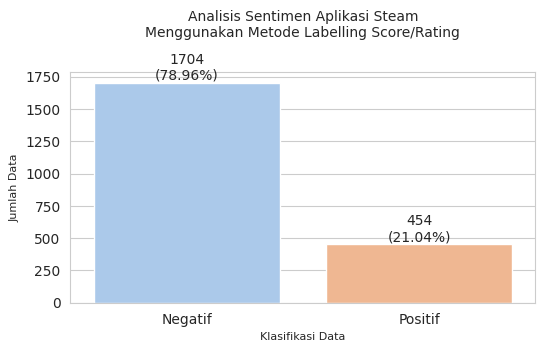

In [ ]:
# Mengimpor pustaka plotting untuk visualisasi data
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Memfilter data agar tidak menampilkan kelas 'Netral'
data_filtered = data[data['Sentiment'] != 'Netral']

# Menghitung jumlah sebaran masing-masing kategori sentimen (tanpa Netral)
sentiment_count = data_filtered['Sentiment'].value_counts()
sns.set_style('whitegrid')

# Membuat grafik batang (bar plot) untuk menampilkan sebaran sentimen
fig, ax = plt.subplots(figsize=(6, 3))
ax = sns.barplot(x=sentiment_count.index, y=sentiment_count.values, palette='pastel')
plt.title('Analisis Sentimen Aplikasi Steam\nMenggunakan Metode Labelling Score/Rating', fontsize=10, pad=25)
plt.xlabel('Klasifikasi Data', fontsize=8)
plt.ylabel('Jumlah Data', fontsize=8)

# Menambahkan teks presentase proporsi data di atas setiap batang grafik
total = len(data_filtered)
for i, count in enumerate(sentiment_count.values):
    percentage = f'{100 * count / total:.2f}%'
    ax.text(i, count + 0.10, f'{count}\n({percentage})', ha='center', va='bottom')

plt.show()

In [ ]:
# Menyimpan dataset yang telah dilengkapi kolom pelabelan sentimen ke file CSV baru
data.to_csv('Hasil_Labelling_Data_2Class.csv',encoding='utf8', index=False)

In [ ]:
# Mengimpor pustaka pandas
import pandas as pd

# Membaca dataset hasil pelabelan sentimen ulasan
data = pd.read_csv("Hasil_Labelling_Data_2Class.csv")
# Menampilkan struktur data beserta beberapa baris pertamanya
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2234 entries, 0 to 2233
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   score             2234 non-null   int64 
 1   content           2234 non-null   object
 2   cleaning          2234 non-null   object
 3   case_folding      2234 non-null   object
 4   normalisasi_kata  2234 non-null   object
 5   tokenize          2234 non-null   object
 6   stopword_removal  2234 non-null   object
 7   stemming          2234 non-null   object
 8   Sentiment         2234 non-null   object
dtypes: int64(1), object(8)
memory usage: 157.2+ KB


,score,content,cleaning,case_folding,normalisasi_kata,tokenize,stopword_removal,stemming,Sentiment
0,1,"useless apk 🤣, can't log in. fitur lupa passwo...",useless apk cant log in fitur lupa password t...,useless apk cant log in fitur lupa password t...,useless apk cant log ini fitur lupa password t...,"['useless', 'apk', 'cant', 'log', 'ini', 'fitu...",useless aplikasi tidak bisa log fitur lupa pas...,useless apk cant log fitur lupa password,Negatif
1,1,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,ga bisa verifikasi kalo gw manusia,tidak bisa verifikasi kalau gue manusia,"['tidak', 'bisa', 'verifikasi', 'kalau', 'gue'...",verifikasi manusia,verifikasi gue manusia,Negatif
2,1,"kok jadi busuk gini, minta reset password udh ...",kok jadi busuk gini minta reset password udh k...,kok jadi busuk gini minta reset password udh k...,kok jadi busuk begini meminta reset password s...,"['kok', 'jadi', 'busuk', 'begini', 'meminta', ...",busuk reset password konfrim gubris costumer s...,busuk reset password konfrim gubris costumer s...,Negatif
3,5,seru,seru,seru,seru,['seru'],seru,seru,Positif
4,1,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,anehhh login di hp malah di sangka di desktop ...,aneh masuk di hp malah di sangka di desktop an...,"['aneh', 'masuk', 'di', 'hp', 'malah', 'di', '...",aneh masuk handphone sangka desktop aneh bersu...,aneh masuk hp sangka desktop aneh sungguh masu...,Negatif


In [ ]:
# Mengambil sampel data hingga maksimal 5000 baris pertama (opsional jika data terlalu besar)
data = data.iloc[:5000]
# Menampilkan struktur dataset setelah pembatasan sampel
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2234 entries, 0 to 2233
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   score             2234 non-null   int64 
 1   content           2234 non-null   object
 2   cleaning          2234 non-null   object
 3   case_folding      2234 non-null   object
 4   normalisasi_kata  2234 non-null   object
 5   tokenize          2234 non-null   object
 6   stopword_removal  2234 non-null   object
 7   stemming          2234 non-null   object
 8   Sentiment         2234 non-null   object
dtypes: int64(1), object(8)
memory usage: 157.2+ KB


# **Pembagian Data Latih dan Data Uji**

---

In [ ]:
# Mengimpor pustaka split data dan pembangun matriks kata
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Membersihkan baris kosong pada ulasan teks
cleaned_data = data.dropna(subset=['stemming'])

# Memfokuskan analisis hanya pada biner sentimen dengan menghapus kelas 'Netral'
cleaned_data = cleaned_data[cleaned_data['Sentiment'] != 'Netral']

# Menentukan variabel independen X (teks ulasan hasil stemming) dan dependen y (label sentimen)
X = cleaned_data['stemming']
y = cleaned_data['Sentiment']

# Membagi data menjadi data latih (80%) dan data uji (20%) secara stratifikasi agar proporsi kelas seimbang
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Menampilkan jumlah baris masing-masing himpunan data latih dan uji
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print('===========================')


Jumlah data training: 1726
Jumlah data testing: 432


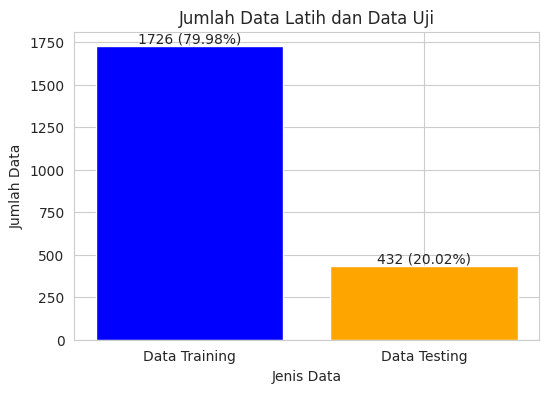

In [ ]:
# Mengimpor pustaka plotting
import matplotlib.pyplot as plt

# Mendapatkan jumlah data latih dan uji
train_size = len(X_train)
test_size = len(X_test)

# Membuat visualisasi bar plot untuk membandingkan jumlah data latih vs data uji
plt.figure(figsize=(6, 4))
bars = plt.bar(['Data Training', 'Data Testing'], [train_size, test_size], color=['blue', 'orange'])

# Menambahkan label teks jumlah sampel beserta persentasenya di atas setiap bar grafik
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 1, f'{height} ({height / (train_size + test_size) * 100:.2f}%)',
             ha='center', va='bottom')

plt.title('Jumlah Data Latih dan Data Uji')
plt.xlabel('Jenis Data')
plt.ylabel('Jumlah Data')
plt.show()

In [ ]:
# Mengimpor TfidfVectorizer dari sklearn
from sklearn.feature_extraction.text import TfidfVectorizer

# Menginisialisasi objek TfidfVectorizer untuk ekstraksi fitur (dengan batasan max_features)
vectorizer = TfidfVectorizer(max_features=2500)

# Mempelajari kosakata dan mengubah data latih menjadi representasi vektor numerik
X_train_vec = vectorizer.fit_transform(X_train)
# Mengubah data uji menggunakan kosakata yang telah dipelajari dari data latih
X_test_vec = vectorizer.transform(X_test)

# Menampilkan bentuk dimensi matriks hasil ekstraksi fitur
print("Dimensi data latih:", X_train_vec.shape)
print("Dimensi data uji:", X_test_vec.shape)

# Menampilkan jumlah fitur unik yang terbentuk setelah proses vektorisasi
print("Jumlah fitur (kolom) setelah vektorisasi:", X_train_vec.shape[1])
print("Jumlah fitur (kolom) setelah vektorisasi:", X_test_vec.shape[1])


Dimensi data latih: (1726, 2476)
Dimensi data uji: (432, 2476)
Jumlah fitur (kolom) setelah vektorisasi: 2476
Jumlah fitur (kolom) setelah vektorisasi: 2476


# **SVM Dan Naive Bayes sebelum SMOTE-Tomek Link**

---

In [ ]:
# Mengimpor model SVM, Naive Bayes, dan metrik evaluasi klasifikasi
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# =========================================
# Inisialisasi Model Sebelum Penyeimbangan
# =========================================
models = {
    "SVM": SVC(kernel='linear', random_state=42),
    "Naive Bayes": MultinomialNB(),
}

# =========================================
# Pelatihan & Evaluasi Model
# =========================================
results = {}

# Melakukan perulangan latih dan prediksi untuk setiap model yang didefinisikan
for model_name, model in models.items():
    model.fit(X_train_vec, y_train) # Melatih model menggunakan data latih
    y_pred = model.predict(X_test_vec) # Memprediksi kelas data uji
    results[model_name] = {
        "accuracy": accuracy_score(y_test, y_pred), # Menyimpan nilai akurasi
        "classification_report": classification_report(y_test, y_pred, output_dict=True), # Menyimpan laporan performa
        "confusion_matrix": confusion_matrix(y_test, y_pred) # Menyimpan matriks kebingungan (confusion matrix)
    }


Confusion Matrix for SVM:


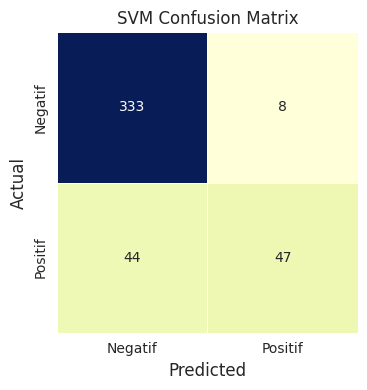


Confusion Matrix for Naive Bayes:


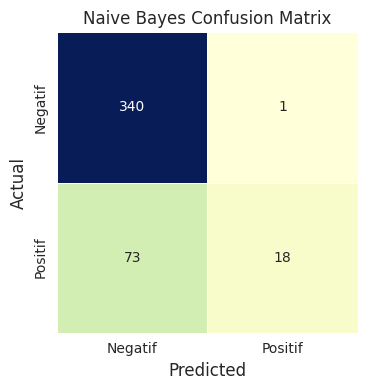

In [ ]:
# Mengimpor pustaka plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Menampilkan visualisasi Confusion Matrix untuk setiap model sebelum penyeimbangan kelas
for model_name, result in results.items():
    fig, ax = plt.subplots(figsize=(4, 4))
    sns.heatmap(
        result["confusion_matrix"],
        annot=True, # Menampilkan angka jumlah prediksi di dalam kotak
        fmt='d',
        cmap="YlGnBu",
        cbar=False,
        xticklabels=['Negatif','Positif'],
        yticklabels=['Negatif','Positif'],
        ax=ax,
        square=True,
        linewidths=0.5
    )
    print(f"\nConfusion Matrix for {model_name}:")
    ax.set_title(f"{model_name} Confusion Matrix", fontsize=12)
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("Actual", fontsize=12)

    plt.tight_layout()
    plt.show()

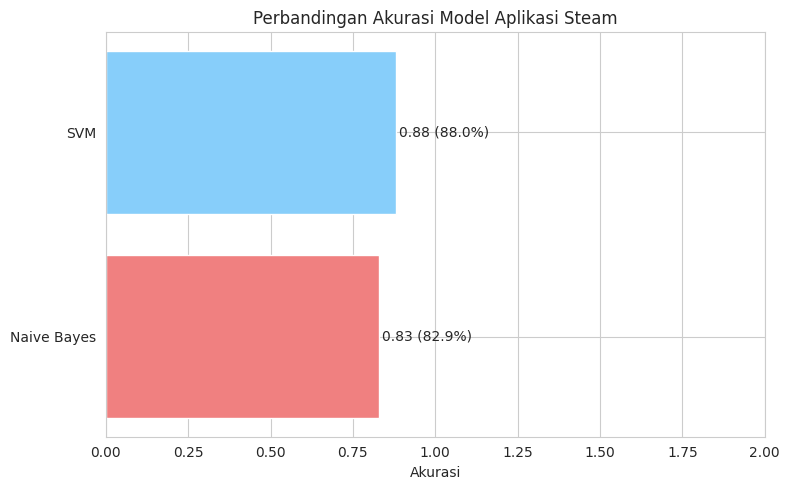

In [ ]:
# Mengimpor pustaka plotting
import matplotlib.pyplot as plt

# Mengambil nilai akurasi setiap model dan mengurutkannya dari yang tertinggi
accuracies = {model: result['accuracy'] for model, result in results.items()}
sorted_accuracies = dict(sorted(accuracies.items(), key=lambda item: item[1], reverse=True))

# Menentukan palet warna cerah
bright_colors = [
    'lightskyblue', 'lightcoral', 'palegreen', 'khaki',
    'plum', 'lightsalmon', 'mediumturquoise', 'wheat'
]

# Menyesuaikan palet warna dengan jumlah model yang dievaluasi
num_models = len(sorted_accuracies)
colors = bright_colors[:num_models] if num_models <= len(bright_colors) else bright_colors * (num_models // len(bright_colors) + 1)

# Menggambar diagram batang horizontal perbandingan akurasi model sebelum balancing
plt.figure(figsize=(8, 5))
bars = plt.barh(
    list(sorted_accuracies.keys()),
    list(sorted_accuracies.values()),
    color=colors[:num_models]
)

# Menambahkan nilai persentase akurasi di samping masing-masing bar
for bar in bars:
    accuracy = bar.get_width()
    plt.text(
        accuracy + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'{accuracy:.2f} ({accuracy * 100:.1f}%)',
        va='center',
        fontsize=10
    )

plt.title("Perbandingan Akurasi Model Aplikasi Steam")
plt.xlabel("Akurasi")
plt.xlim(0, 2)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Mengimpor fungsi penampil interaktif
from IPython.display import display

# Menampilkan laporan metrik lengkap (Precision, Recall, F1-Score) bergradasi warna untuk tiap model sebelum balancing
for model_name, result in results.items():
    print(f"\nClassification Report for {model_name}:")

    # Mengubah struktur dictionary laporan klasifikasi menjadi DataFrame
    report_df = pd.DataFrame(result['classification_report']).transpose()

    # Memberikan pewarnaan latar belakang berbasis nilai metrik klasifikasi
    styled_df = report_df.style.background_gradient(cmap="coolwarm")
    styled_df = styled_df.format(precision=3)
    display(styled_df)


Classification Report for SVM:


,precision,recall,f1-score,support
Negatif,0.883,0.977,0.928,341.000
Positif,0.855,0.516,0.644,91.000
accuracy,0.880,0.880,0.880,0.880
macro avg,0.869,0.747,0.786,432.000
weighted avg,0.877,0.880,0.868,432.000



Classification Report for Naive Bayes:


,precision,recall,f1-score,support
Negatif,0.823,0.997,0.902,341.000
Positif,0.947,0.198,0.327,91.000
accuracy,0.829,0.829,0.829,0.829
macro avg,0.885,0.597,0.615,432.000
weighted avg,0.849,0.829,0.781,432.000


### **Hybrid Sampling (SMOTE + Tomek Links) Khusus pada Data Training**

---

In [ ]:
# Mengimpor pustaka manipulasi data dan teknik over/under sampling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek

# 1. Mengekstrak fitur teks menggunakan metode TF-IDF dengan batas maksimal 2500 dimensi kata kunci
tfidf_vectorizer = TfidfVectorizer(max_features=2500)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Menampilkan distribusi label sentimen pada data training asli sebelum penyeimbangan kelas
print("=== Distribusi Awal Data Training ===")
print(y_train.value_counts())

# Menentukan target jumlah penyeimbangan sampel kelas mayoritas dan kelas minoritas
under_strategy = {'Negatif': 1100}
over_strategy = {'Positif': 1100}

# Langkah A: Downsampling kelas mayoritas (Sentimen Negatif) ke target 1100 data
rus = RandomUnderSampler(sampling_strategy=under_strategy, random_state=42)
X_train_res1, y_train_res1 = rus.fit_resample(X_train_tfidf, y_train)

# Langkah B: Menerapkan algoritma gabungan SMOTE untuk oversampling kelas minoritas (Positif) dan Tomek Links untuk reduksi noise batas kelas
smote_tomek = SMOTETomek(
    smote=SMOTE(sampling_strategy=over_strategy, random_state=42),
    random_state=42
)

# Mendapatkan fitur training baru yang telah seimbang
X_train_balanced, y_train_balanced = smote_tomek.fit_resample(X_train_res1, y_train_res1)

# Menampilkan sebaran data baru yang sudah seimbang
print("\n=== Distribusi Akhir Data Training setelah SMOTE + Tomek ===")
print(y_train_balanced.value_counts())

=== Distribusi Awal Data Training ===
Sentiment
Negatif    1363
Positif     363
Name: count, dtype: int64

=== Distribusi Akhir Data Training setelah SMOTE + Tomek ===
Sentiment
Negatif    1097
Positif    1097
Name: count, dtype: int64


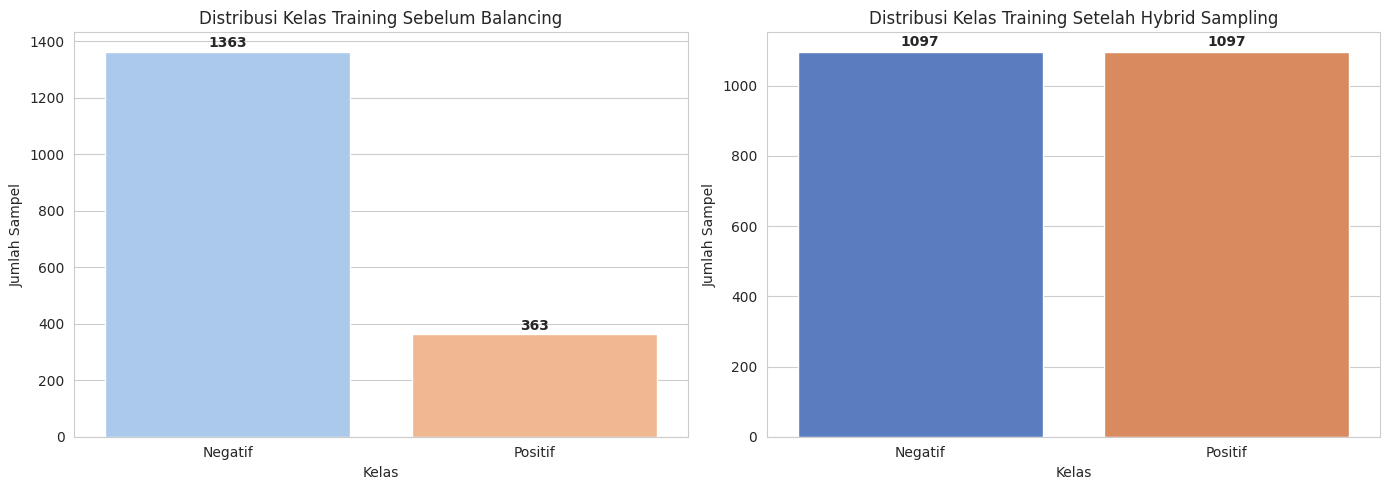

In [ ]:
# Membuat visualisasi grafik batang perbandingan distribusi kelas sebelum dan sesudah balancing
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.set_style('whitegrid')

# Subplot kiri: Distribusi kelas latih sebelum dilakukan proses balancing
sns.barplot(
    x=y_train.value_counts().index,
    y=y_train.value_counts().values,
    ax=axes[0],
    palette='pastel'
)
axes[0].set_title('Distribusi Kelas Training Sebelum Balancing', fontsize=12)
axes[0].set_xlabel('Kelas')
axes[0].set_ylabel('Jumlah Sampel')
for i, v in enumerate(y_train.value_counts().values):
    axes[0].text(i, v + 15, f"{v}", ha='center', fontweight='bold')

# Subplot kanan: Distribusi kelas latih sesudah dilakukan balancing menggunakan SMOTE + Tomek
sns.barplot(
    x=y_train_balanced.value_counts().index,
    y=y_train_balanced.value_counts().values,
    ax=axes[1],
    palette='muted'
)
axes[1].set_title('Distribusi Kelas Training Setelah Hybrid Sampling', fontsize=12)
axes[1].set_xlabel('Kelas')
axes[1].set_ylabel('Jumlah Sampel')
for i, v in enumerate(y_train_balanced.value_counts().values):
    axes[1].text(i, v + 15, f"{v}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### **Evaluasi Model Setelah Penyeimbangan Data (SMOTE + Tomek)**

---


Confusion Matrix for SVM (Balanced):


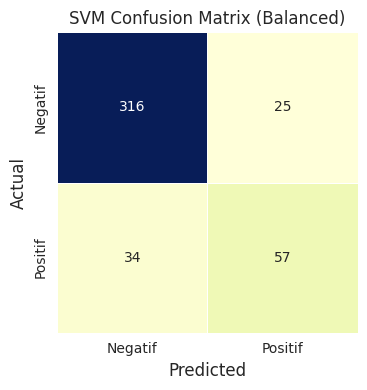


Confusion Matrix for Naive Bayes (Balanced):


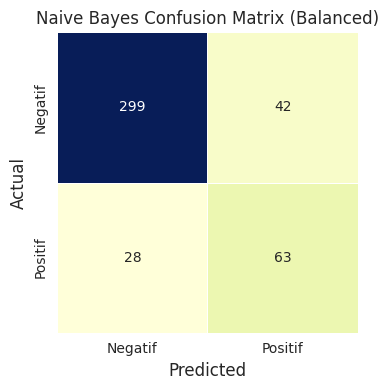

In [ ]:
# Mengimpor metrik evaluasi dan algoritma SVM serta Naive Bayes
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB

# Mendefinisikan ulang kamus model
balanced_models = {
    "SVM": SVC(kernel='linear', random_state=42),
    "Naive Bayes": MultinomialNB(),
}

# Melatih ulang model klasifikasi menggunakan dataset seimbang (X_train_balanced) dan memprediksi data uji murni (X_test_tfidf)
for model_name, model in balanced_models.items():
    model.fit(X_train_balanced, y_train_balanced) # Melatih model seimbang
    y_pred = model.predict(X_test_tfidf) # Memprediksi data uji murni
    cm = confusion_matrix(y_test, y_pred) # Membuat matriks kebingungan baru

    # Visualisasi matriks kebingungan baru untuk masing-masing model pasca penyeimbangan data
    fig, ax = plt.subplots(figsize=(4, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap="YlGnBu",
        cbar=False,
        xticklabels=['Negatif','Positif'],
        yticklabels=['Negatif','Positif'],
        ax=ax,
        square=True,
        linewidths=0.5
    )
    print(f"\nConfusion Matrix for {model_name} (Balanced):")
    ax.set_title(f"{model_name} Confusion Matrix (Balanced)", fontsize=12)
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("Actual", fontsize=12)

    plt.tight_layout()
    plt.show()

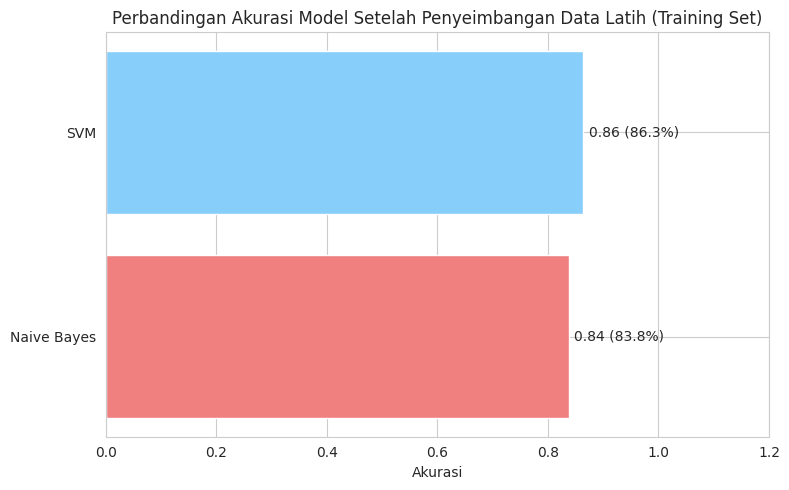

In [ ]:
# Melatih ulang semua model dengan data training yang sudah seimbang untuk melihat skor akurasi pasca penyeimbangan
from sklearn.svm import SVC

balanced_results = {}

# Inisialisasi ulang model klasifikasi biner
balanced_models = {
    "SVM": SVC(kernel='linear', random_state=42),
    "Naive Bayes": MultinomialNB(),
}

# Proses latih ulang dan penghitungan metrik klasifikasi pasca balancing
for model_name, model in balanced_models.items():
    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_tfidf)
    balanced_results[model_name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "classification_report": classification_report(y_test, y_pred, output_dict=True)
    }

# Mengurutkan nilai akurasi baru dari yang tertinggi
sorted_bal_accuracies = dict(sorted({m: r['accuracy'] for m, r in balanced_results.items()}.items(), key=lambda x: x[1], reverse=True))

# Visualisasi grafik batang horizontal akurasi model pasca balancing data
plt.figure(figsize=(8, 5))
bars = plt.barh(
    list(sorted_bal_accuracies.keys()),
    list(sorted_bal_accuracies.values()),
    color=bright_colors[:len(sorted_bal_accuracies)]
)

# Menambahkan persentase angka akurasi pada bar grafik horizontal baru
for bar in bars:
    accuracy = bar.get_width()
    plt.text(
        accuracy + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'{accuracy:.2f} ({accuracy * 100:.1f}%)',
        va='center',
        fontsize=10
    )

plt.title("Perbandingan Akurasi Model Setelah Penyeimbangan Data Latih (Training Set)")
plt.xlabel("Akurasi")
plt.xlim(0, 1.2)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Mengimpor pustaka display dan pandas
from IPython.display import display
import pandas as pd

# Menampilkan laporan metrik precision-recall lengkap dan bergradasi warna untuk model yang telah dilatih ulang pada data seimbang
for model_name, result in balanced_results.items():
    print(f"\nClassification Report for {model_name} (Balanced):")

    # Mengonversi format dictionary laporan metrik menjadi DataFrame
    report_df = pd.DataFrame(result['classification_report']).transpose()

    # Menampilkan tabel interaktif berwarna sesuai performa klasifikasi
    styled_df = report_df.style.background_gradient(cmap="coolwarm")
    styled_df = styled_df.format(precision=3)
    display(styled_df)


Classification Report for SVM (Balanced):


,precision,recall,f1-score,support
Negatif,0.903,0.927,0.915,341.000
Positif,0.695,0.626,0.659,91.000
accuracy,0.863,0.863,0.863,0.863
macro avg,0.799,0.777,0.787,432.000
weighted avg,0.859,0.863,0.861,432.000



Classification Report for Naive Bayes (Balanced):


,precision,recall,f1-score,support
Negatif,0.914,0.877,0.895,341.000
Positif,0.600,0.692,0.643,91.000
accuracy,0.838,0.838,0.838,0.838
macro avg,0.757,0.785,0.769,432.000
weighted avg,0.848,0.838,0.842,432.000


### **Visualisasi Perbandingan Kinerja Model (Tanpa vs Dengan SMOTE-Tomek)**


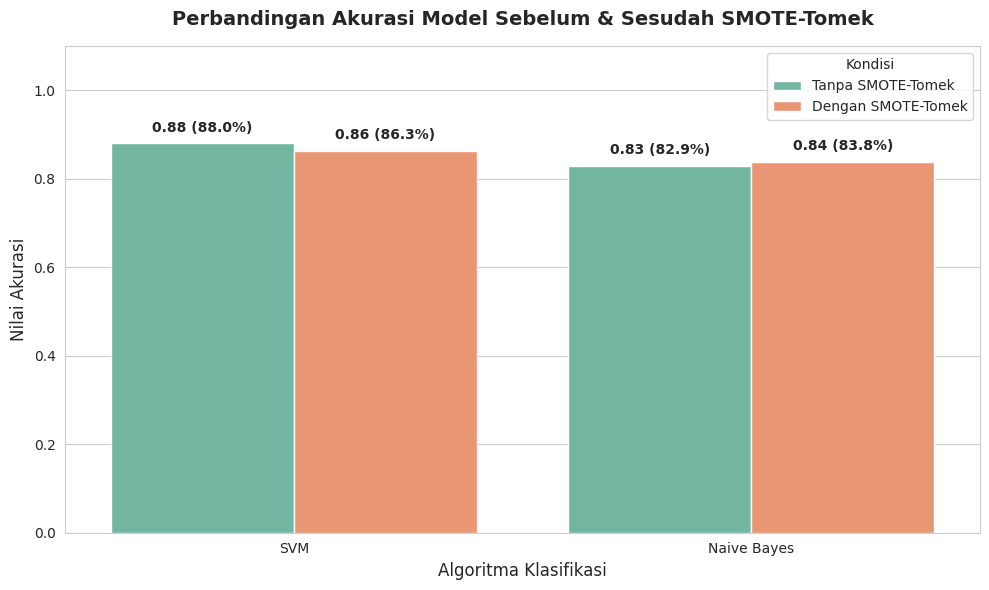

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Mengambil nilai akurasi dari hasil eksperimen sebelumnya
accuracy_comparison = {
    'Model': ['SVM', 'Naive Bayes', 'SVM', 'Naive Bayes'],
    'Kondisi': ['Tanpa SMOTE-Tomek', 'Tanpa SMOTE-Tomek', 'Dengan SMOTE-Tomek', 'Dengan SMOTE-Tomek'],
    'Akurasi': [
        results['SVM']['accuracy'],
        results['Naive Bayes']['accuracy'],
        balanced_results['SVM']['accuracy'],
        balanced_results['Naive Bayes']['accuracy']
    ]
}

# Mengubah ke dalam bentuk DataFrame pandas
df_compare = pd.DataFrame(accuracy_comparison)

# Mengatur ukuran jendela grafik
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')

# Membuat diagram batang berdampingan
ax = sns.barplot(x='Model', y='Akurasi', hue='Kondisi', data=df_compare, palette='Set2')

# Menambahkan judul dan label sumbu
plt.title('Perbandingan Akurasi Model Sebelum & Sesudah SMOTE-Tomek', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Algoritma Klasifikasi', fontsize=12)
plt.ylabel('Nilai Akurasi', fontsize=12)
plt.ylim(0, 1.1)

# Menambahkan label teks nilai akurasi di atas setiap batang grafik
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.text(
            p.get_x() + p.get_width() / 2.0,
            height + 0.02,
            f'{height:.2f} ({height * 100:.1f}%)',
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )

# Menampilkan grafik visualisasi
plt.tight_layout()
plt.show()

### **WordCloud Sentimen Positif vs Negatif**

Visualisasi kata-kata yang paling sering muncul pada masing-masing kategori sentimen (tanpa sentimen Netral).

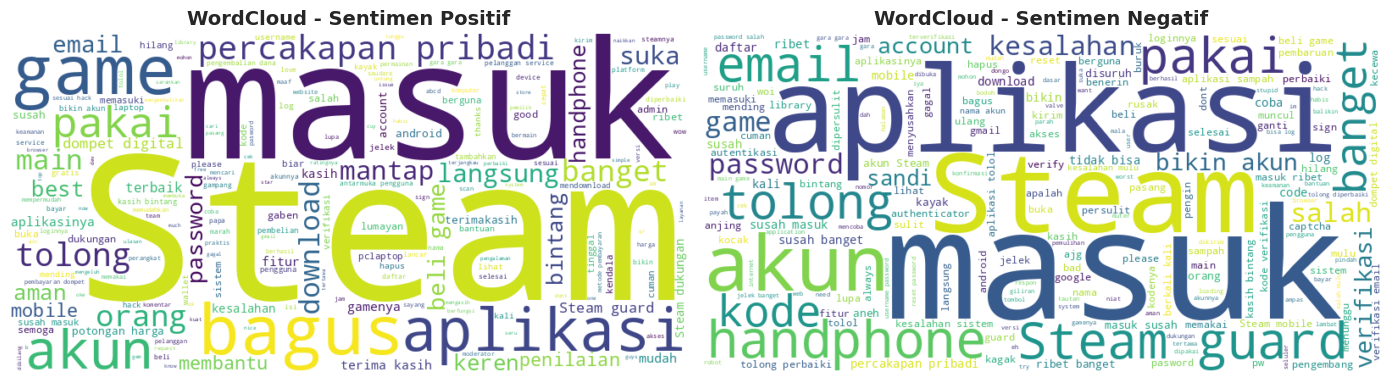

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Memfilter data hanya untuk sentimen Positif dan Negatif
df_wc = data[data['Sentiment'].isin(['Positif', 'Negatif'])]

# Menggabungkan teks untuk masing-masing sentimen
text_positif = " ".join(df_wc[df_wc['Sentiment'] == 'Positif']['stopword_removal'].astype(str))
text_negatif = " ".join(df_wc[df_wc['Sentiment'] == 'Negatif']['stopword_removal'].astype(str))

# Membuat objek WordCloud untuk masing-masing sentimen dengan parameter latar belakang, resolusi, jumlah kata maksimum, dan skema warna
wc_positif = WordCloud(background_color="white", width=800, height=400, max_words=200).generate(text_positif)
wc_negatif = WordCloud(background_color="white", width=800, height=400, max_words=200).generate(text_negatif)

# Mengatur ukuran jendela gambar (figure) untuk visualisasi kedua WordCloud berdampingan
plt.figure(figsize=(14, 6))

# Membuat subplot pertama (sebelah kiri) untuk menampilkan WordCloud sentimen Positif
plt.subplot(1, 2, 1)
plt.imshow(wc_positif, interpolation='bilinear') # Menampilkan gambar WordCloud
plt.axis("off") # Menghilangkan garis sumbu koordinat (axis x dan y)
plt.title("WordCloud - Sentimen Positif", fontsize=14, fontweight='bold') # Menambahkan judul sub-gambar

# Membuat subplot kedua (sebelah kanan) untuk menampilkan WordCloud sentimen Negatif
plt.subplot(1, 2, 2)
plt.imshow(wc_negatif, interpolation='bilinear') # Menampilkan gambar WordCloud
plt.axis("off") # Menghilangkan garis sumbu koordinat (axis x dan y)
plt.title("WordCloud - Sentimen Negatif", fontsize=14, fontweight='bold') # Menambahkan judul sub-gambar

# Mengatur tata letak tata gambar agar rapi dan tidak saling bertabrakan
plt.tight_layout()
# Menampilkan hasil visualisasi gambar secara keseluruhan
plt.show()